In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np
import re

# 1. Load data
# Support both a project-root kernel and a notebook-directory kernel.
project_candidates = (Path.cwd(), Path.cwd() / "server", Path.cwd().parent)
PROJECT_DIR = next(
    (candidate.resolve() for candidate in project_candidates
     if (candidate / "data" / "cars.csv").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Could not locate server/data/cars.csv from the current directory")

df = pd.read_csv(PROJECT_DIR / "data" / "cars.csv", encoding='latin1')

# 2. Basic column cleaning
df.rename(columns={'CC/Battery Capacity':'battery_capacity','Performance(0 - 100 )KM/H':'performance'}, inplace=True)
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df = df.drop_duplicates()

# Strip extra spaces from object columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# 3. Define range handling function
def handle_range(val):
    if pd.isna(val):
        return np.nan
    s = str(val).replace(',', '')
    nums = re.findall(r'\d+\.?\d*', s)
    if len(nums) == 0:
        return np.nan
    nums = list(map(float, nums))
    return np.mean(nums)

# 4. Clean numeric columns
# battery_capacity
df['battery_capacity'] = df['battery_capacity'].astype(str).str.replace('cc', '', regex=False)
df['battery_capacity'] = df['battery_capacity'].apply(handle_range)

# horsepower
df['horsepower'] = df['horsepower'].astype(str).str.replace('hp', '', regex=False)
df['horsepower'] = df['horsepower'].apply(handle_range)

# total_speed
df['total_speed'] = df['total_speed'].astype(str).str.replace('km/h', '', regex=False)
df['total_speed'] = df['total_speed'].apply(handle_range)

# performance (and inversion)
df['performance'] = df['performance'].astype(str).str.replace('sec', '', regex=False)
df['performance'] = df['performance'].apply(handle_range)
df['performance'] = 1 / df['performance']

# cars_prices
df['cars_prices'] = df['cars_prices'].astype(str).str.replace('USD', '', regex=False).str.replace('usd', '', regex=False).str.replace('$', '', regex=False)
df['cars_prices'] = df['cars_prices'].apply(handle_range)

# torque
df['torque'] = df['torque'].astype(str).str.replace('Nm', '', regex=False)
df['torque'] = df['torque'].apply(handle_range)

# seats (handling 2+2 and ranges)
df['seats'] = df['seats'].astype(str).str.replace(r'2\+2', '4', regex=True)
df['seats'] = df['seats'].apply(handle_range)

# 5. Impute missing values with medians
numeric_cols = ['battery_capacity', 'horsepower', 'total_speed', 'performance', 'cars_prices', 'torque', 'seats']
for col in numeric_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# 6. Final standardized categorical cleaning
df['company_names'] = df['company_names'].str.upper()
df = df.reset_index(drop=True)

print(df.info())
print(df.describe())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1214 entries, 0 to 1213
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   company_names     1214 non-null   object 
 1   cars_names        1214 non-null   object 
 2   engines           1214 non-null   object 
 3   battery_capacity  1214 non-null   float64
 4   horsepower        1214 non-null   float64
 5   total_speed       1214 non-null   float64
 6   performance       1214 non-null   float64
 7   cars_prices       1214 non-null   float64
 8   fuel_types        1214 non-null   object 
 9   seats             1214 non-null   float64
 10  torque            1214 non-null   float64
dtypes: float64(7), object(4)
memory usage: 104.5+ KB
None
       battery_capacity   horsepower  total_speed  performance   cars_prices  \
count       1214.000000  1214.000000  1214.000000  1214.000000  1.214000e+03   
mean        2702.477412   307.812603   216.581549     0.160129 

**Reasoning**:
Based on the `df.info()` output, several numerical columns (`battery_capacity`, `performance`, `cars_prices`, `torque`) still have a few missing values. To prepare the data for K-means clustering, which typically requires complete numerical data, I will impute these missing values with the median of their respective columns. The median is chosen to be robust to potential outliers, as suggested by the statistical summaries from `df.describe()` for columns like `cars_prices` and `torque`.



In [ ]:
for col in ['battery_capacity', 'performance', 'cars_prices', 'torque']:
    df[col].fillna(df[col].median(), inplace=True)

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1214 entries, 0 to 1213
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   company_names     1214 non-null   object 
 1   cars_names        1214 non-null   object 
 2   engines           1214 non-null   object 
 3   battery_capacity  1214 non-null   float64
 4   horsepower        1214 non-null   float64
 5   total_speed       1214 non-null   float64
 6   performance       1214 non-null   float64
 7   cars_prices       1214 non-null   float64
 8   fuel_types        1214 non-null   object 
 9   seats             1214 non-null   float64
 10  torque            1214 non-null   float64
dtypes: float64(7), object(4)
memory usage: 104.5+ KB
None


/tmp/ipykernel_307/1165957899.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


**Reasoning**:
The previous code produced a `FutureWarning` regarding the use of `inplace=True` with chained assignment. To ensure robustness and avoid future issues, I will replace `df[col].fillna(df[col].median(), inplace=True)` with `df[col] = df[col].fillna(df[col].median())` to directly assign the filled values back to the column.



In [ ]:
for col in ['battery_capacity', 'performance', 'cars_prices', 'torque']:
    df[col] = df[col].fillna(df[col].median())

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1214 entries, 0 to 1213
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   company_names     1214 non-null   object 
 1   cars_names        1214 non-null   object 
 2   engines           1214 non-null   object 
 3   battery_capacity  1214 non-null   float64
 4   horsepower        1214 non-null   float64
 5   total_speed       1214 non-null   float64
 6   performance       1214 non-null   float64
 7   cars_prices       1214 non-null   float64
 8   fuel_types        1214 non-null   object 
 9   seats             1214 non-null   float64
 10  torque            1214 non-null   float64
dtypes: float64(7), object(4)
memory usage: 104.5+ KB
None


**Reasoning**:
With the numerical columns cleaned and missing values imputed, I will now inspect the categorical (object) columns to identify any inconsistencies, unique values, or categories that may require further cleaning or encoding before feature selection for clustering. This will involve checking the unique values and their counts for 'company_names', 'cars_names', 'engines', 'fuel_types', and 'seats'.



In [ ]:
for col in df.select_dtypes(include='object').columns:
    print(f"Value counts for column: {col}")
    print(df[col].value_counts())
    print("\n" + "-"*50 + "\n")

Value counts for column: company_names
company_names
NISSAN               159
VOLKSWAGEN           107
PORSCHE               96
MAZDA                 87
KIA                   71
MITSUBISHI            60
GMC                   59
CHEVROLET             57
PEUGEOT               54
FORD                  54
TOYOTA                50
BMW                   41
JAGUAR LAND ROVER     40
ROLLS ROYCE           30
TATA MOTORS           28
ACURA                 27
LAMBORGHINI           24
HYUNDAI               23
AUDI                  21
MERCEDES              21
CADILLAC              20
JEEP                  19
VOLVO                 12
ASTON MARTIN          11
TESLA                 10
BUGATTI               10
FERRARI                9
HONDA                  7
MARUTI SUZUKI          3
MAHINDRA               3
BENTLEY                1
Name: count, dtype: int64

--------------------------------------------------

Value counts for column: cars_names
cars_names
Malibu Premier    2
MIRAI             2
KA+   

**Reasoning**:
Based on the value counts, the `company_names` column has inconsistencies due to varying capitalization (e.g., 'TOYOTA' vs 'Toyota'). To standardize these entries and reduce redundancy, I will convert all company names to uppercase.



In [ ]:
df['company_names'] = df['company_names'].str.upper()

print(df['company_names'].value_counts())


company_names
NISSAN               159
VOLKSWAGEN           107
PORSCHE               96
MAZDA                 87
KIA                   71
MITSUBISHI            60
GMC                   59
CHEVROLET             57
PEUGEOT               54
FORD                  54
TOYOTA                50
BMW                   41
JAGUAR LAND ROVER     40
ROLLS ROYCE           30
TATA MOTORS           28
ACURA                 27
LAMBORGHINI           24
HYUNDAI               23
AUDI                  21
MERCEDES              21
CADILLAC              20
JEEP                  19
VOLVO                 12
ASTON MARTIN          11
TESLA                 10
BUGATTI               10
FERRARI                9
HONDA                  7
MARUTI SUZUKI          3
MAHINDRA               3
BENTLEY                1
Name: count, dtype: int64


In [ ]:
df['fuel_types'] = df['fuel_types'].str.lower()
df['fuel_types'] = df['fuel_types'].str.replace('plug in hyrbrid', 'plug-in hybrid', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('petrol, hybrid', 'petrol/hybrid', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('petrol, diesel', 'petrol/diesel', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('hybrid (petrol)', 'petrol/hybrid', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('diesel/petrol', 'petrol/diesel', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('hybrid/petrol', 'petrol/hybrid', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('petrol (hybrid)', 'petrol/hybrid', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('gas / hybrid', 'petrol/hybrid', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('hybrid (gas + electric)', 'petrol/electric', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('hybrid/electric', 'petrol/electric', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('petrol/ev', 'petrol/electric', regex=False)
df['fuel_types'] = df['fuel_types'].str.replace('2.5l hybrid / plug-in hybrid', 'plug-in hybrid', regex=False)


print(df['fuel_types'].value_counts())


fuel_types
petrol              869
diesel              106
electric             96
hybrid               78
petrol/hybrid        25
petrol/diesel        23
plug-in hybrid        6
hydrogen              3
petrol/electric       3
petrol/awd            2
cng/petrol            1
diesel hybrid         1
hybrid / plug-in      1
Name: count, dtype: int64


In [ ]:
df['seats'] = df['seats'].astype(str).str.replace('2\+2', '4', regex=True)
df['seats'] = df['seats'].apply(handle_range)

print(df['seats'].value_counts())
print(df.info())

seats
5.0     690
4.0     167
7.0     147
2.0     136
8.0      29
6.0      20
3.0      14
1.0       3
12.0      1
15.0      1
20.0      1
9.0       1
8.5       1
4.5       1
7.5       1
5.5       1
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1214 entries, 0 to 1213
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   company_names     1214 non-null   object 
 1   cars_names        1214 non-null   object 
 2   engines           1214 non-null   object 
 3   battery_capacity  1214 non-null   float64
 4   horsepower        1214 non-null   float64
 5   total_speed       1214 non-null   float64
 6   performance       1214 non-null   float64
 7   cars_prices       1214 non-null   float64
 8   fuel_types        1214 non-null   object 
 9   seats             1214 non-null   float64
 10  torque            1214 non-null   float64
dtypes: float64(7), object(4)
memory usage: 104.5+ KB
None

<>:1: SyntaxWarning: invalid escape sequence '\+'
<>:1: SyntaxWarning: invalid escape sequence '\+'
/tmp/ipykernel_307/3409471746.py:1: SyntaxWarning: invalid escape sequence '\+'
  df['seats'] = df['seats'].astype(str).str.replace('2\+2', '4', regex=True)


In [ ]:
df['seats'] = df['seats'].astype(str).str.replace(r'2\+2', '4', regex=True)
df['seats'] = df['seats'].apply(handle_range)

print(df['seats'].value_counts())
print(df.info())

seats
5.0     690
4.0     167
7.0     147
2.0     136
8.0      29
6.0      20
3.0      14
1.0       3
12.0      1
15.0      1
20.0      1
9.0       1
8.5       1
4.5       1
7.5       1
5.5       1
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1214 entries, 0 to 1213
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   company_names     1214 non-null   object 
 1   cars_names        1214 non-null   object 
 2   engines           1214 non-null   object 
 3   battery_capacity  1214 non-null   float64
 4   horsepower        1214 non-null   float64
 5   total_speed       1214 non-null   float64
 6   performance       1214 non-null   float64
 7   cars_prices       1214 non-null   float64
 8   fuel_types        1214 non-null   object 
 9   seats             1214 non-null   float64
 10  torque            1214 non-null   float64
dtypes: float64(7), object(4)
memory usage: 104.5+ KB
None

In [ ]:
from sklearn.preprocessing import StandardScaler

# Define the numerical columns for scaling
numerical_cols = ['battery_capacity', 'horsepower', 'total_speed', 'performance', 'cars_prices', 'seats', 'torque']

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit and transform the numerical columns from the cleaned df
# Ensuring all columns are numeric and missing values are handled from the previous step
scaled_values = scaler.fit_transform(df[numerical_cols])

# Create the df_scaled DataFrame
df_scaled = pd.DataFrame(scaled_values, columns=numerical_cols)

# Display the first few rows to confirm successful transformation
print("Scaled DataFrame head:")
print(df_scaled.head())
print("\nScale summary:")
print(df_scaled.describe().round(2))

Scaled DataFrame head:
   battery_capacity  horsepower  total_speed  performance  cars_prices  \
0          0.664287    2.940482     2.327175     3.150089     1.351443   
1          2.087770    1.145281     0.630137     0.374930     0.452070   
2         -0.775191   -1.033643    -0.972620    -0.852181    -0.175383   
3          0.660159    1.445978     0.630137     2.001000     0.031894   
4          1.290640    1.320313     1.950055     1.545012     0.161587   

      seats    torque  
0 -1.899599  0.278448  
1  0.094159  0.373662  
2  0.094159 -0.369011  
3 -0.570427  0.373662  
4 -1.899599  0.049933  

Scale summary:
       battery_capacity  horsepower  total_speed  performance  cars_prices  \
count           1214.00     1214.00      1214.00      1214.00      1214.00   
mean               0.00       -0.00         0.00        -0.00         0.00   
std                1.00        1.00         1.00         1.00         1.00   
min               -1.39       -1.26        -2.58        -1.7

## Determine Optimal K (Elbow Method)

### Subtask:
Apply the Elbow Method to determine the optimal number of clusters (K). Calculate the Within-Cluster Sum of Squares (WCSS) for a range of K values, ensuring that K is always >= 3. Plot the WCSS against K to identify the 'elbow point'.


**Reasoning**:
To apply the Elbow Method, I need to import KMeans from sklearn and matplotlib for plotting. I will then calculate the WCSS for a range of K values (from 3 to 15) by fitting KMeans models to the scaled data and store these values. Finally, I will plot the WCSS values against the number of clusters to visualize the elbow point.



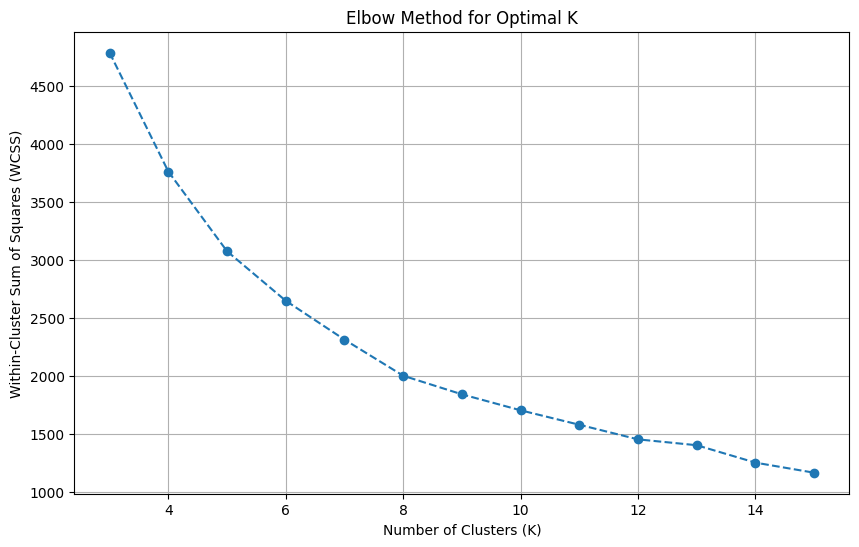

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []
max_k = 15

for i in range(3, max_k + 1):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(3, max_k + 1), wcss, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.title('Elbow Method for Optimal K')
plt.grid(True)
plt.show()

In [ ]:
import plotly.express as px
from sklearn.cluster import KMeans

# Ensure cluster column exists by re-applying the optimal model
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(df_scaled)

# Create the scatter matrix
fig = px.scatter_matrix(
    df,
    dimensions=['battery_capacity', 'horsepower', 'total_speed', 'performance', 'cars_prices'],
    color='cluster',
    title='Cluster Relationships with Scatter Matrix',
    hover_data=['company_names', 'cars_names']
)
fig.update_traces(diagonal_visible=False)
fig.show()

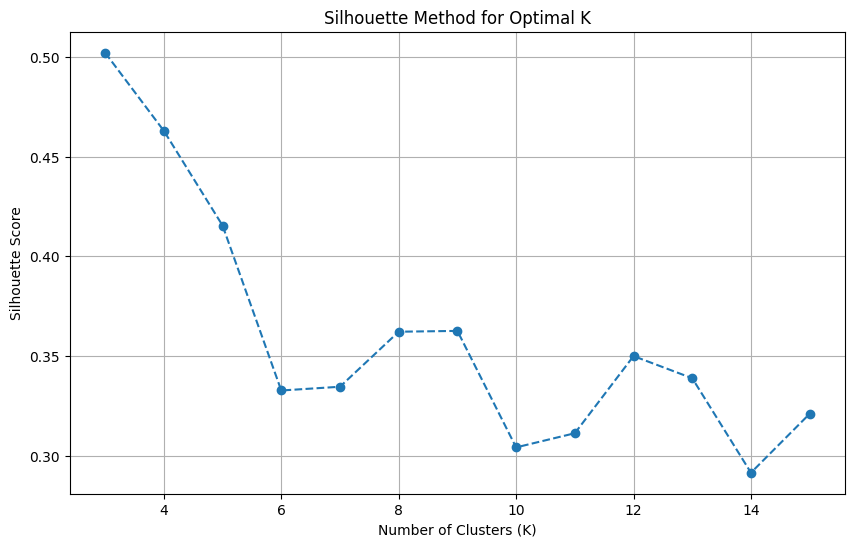

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for i in range(3, max_k + 1):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    silhouette_scores.append(silhouette_score(df_scaled, kmeans.labels_))

plt.figure(figsize=(10, 6))
plt.plot(range(3, max_k + 1), silhouette_scores, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Method for Optimal K')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans

# Instantiate KMeans with optimal K=3
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)

# Fit the model to the scaled data
kmeans.fit(df_scaled)

# Assign the cluster labels to the original DataFrame
df['cluster'] = kmeans.labels_

# Print the value counts for the new 'cluster' column
print("Cluster distribution:")
print(df['cluster'].value_counts())


Cluster distribution:
cluster
1    783
0    235
4    177
2     13
3      6
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt

k_values = list(range(5, max_k + 1))

# Find the optimal k value
optimal_k_index = silhouette_scores.index(max(silhouette_scores))
optimal_k = k_values[optimal_k_index]
max_silhouette_score = silhouette_scores[optimal_k_index]


print(f"The optimal number of clusters (k) is: {optimal_k}")
print(f"The highest Silhouette Score is: {max_silhouette_score:.4f}")

The optimal number of clusters (k) is: 5
The highest Silhouette Score is: 0.5021


In [ ]:
pd.options.display.float_format = '{:,.0f}'.format

In [ ]:
cluster1 = df[df["cluster"] == 0]
cluster1.describe()

,battery_capacity,horsepower,total_speed,performance,cars_prices,seats,torque,cluster
count,235,235,235,235,235,235,235,235
mean,"3,602",539,288,0,"215,462",4,663,0
std,"1,737",140,35,0,"277,888",1,177,0
min,12,248,170,0,"30,000",1,366,0
25%,"2,894",434,250,0,"86,500",2,528,0
50%,"3,745",541,290,0,"130,000",4,650,0
75%,"4,096",624,315,0,"240,650",5,770,0
max,"6,749","1,020",362,0,"2,800,000",7,"1,400",0


In [ ]:
cluster2 = df[df["cluster"] == 1]
cluster2.describe()

,battery_capacity,horsepower,total_speed,performance,cars_prices,seats,torque,cluster
count,783,783,783,783,783,783,783,783
mean,"1,762",194,196,0,"34,843",5,302,1
std,854,86,32,0,"17,007",1,136,0
min,1,26,80,0,"4,000",2,45,1
25%,"1,340",134,180,0,"23,000",5,200,1
50%,"1,796",181,195,0,"32,000",5,275,1
75%,"2,200",250,217,0,"44,000",5,400,1
max,"5,552",754,272,0,"150,000",9,"1,064",1


In [ ]:
cluster3 = df[df["cluster"] == 2]
cluster3.describe()

,battery_capacity,horsepower,total_speed,performance,cars_prices,seats,torque,cluster
count,13,13,13,13,13,13,13,13
mean,"7,350","1,405",406,0,"5,569,231",2,"1,392",2
std,"1,527",336,51,0,"4,093,569",0,404,0
min,"2,620",700,320,0,"3,000,000",1,500,2
25%,"7,993","1,500",380,0,"3,300,000",2,"1,600",2
50%,"7,993","1,500",420,0,"4,500,000",2,"1,600",2
75%,"7,993","1,600",420,0,"5,800,000",2,"1,600",2
max,"7,993","1,850",500,0,"18,000,000",2,"1,600",2


In [ ]:
cluster4 = df[df["cluster"] == 3]
cluster4.describe()

,battery_capacity,horsepower,total_speed,performance,cars_prices,seats,torque,cluster
count,6,6,6,6,6,6,6,6
mean,200,963,209,0,"120,133",5,"14,658",3
std,0,180,95,0,"39,694",0,"2,282",0
min,200,830,170,0,"96,550",4,"10,000",3
25%,200,830,170,0,"98,662",5,"15,590",3
50%,200,915,170,0,"107,500",5,"15,590",3
75%,200,"1,000",170,0,"112,025",5,"15,590",3
max,200,"1,288",402,1,"200,000",5,"15,590",3


In [ ]:
cluster5 = df[df["cluster"] == 4]
cluster5.describe()

,battery_capacity,horsepower,total_speed,performance,cars_prices,seats,torque,cluster
count,177,177,177,177,177,177,177,177
mean,"5,411",399,200,0,"95,277",6,665,4
std,"2,075",184,33,0,"101,529",2,444,0
min,"2,000",134,90,0,"28,000",2,330,4
25%,"3,600",310,180,0,"50,000",5,413,4
50%,"5,327",392,200,0,"61,750",7,560,4
75%,"6,400",428,210,0,"82,295",7,650,4
max,"16,100","2,488",250,0,"515,000",20,"3,500",4


In [ ]:
import plotly.express as px

# แปลง cluster เป็น string เพื่อให้สีในกราฟเป็นแบบ Discrete
df['cluster_label'] = df['cluster'].astype(str)

fig = px.scatter(
    df,
    x='total_speed',
    y='horsepower',
    color='cluster_label',
    # นำ size='cars_prices' ออกเพื่อให้ทุกจุดเท่ากัน
    hover_data=['company_names', 'cars_names', 'fuel_types', 'cars_prices'],
    title='<b>Advanced Car Segmentation Analysis</b><br><sup>Total Speed vs Horsepower (Uniform Dot Size)</sup>',
    labels={'total_speed': 'Total Speed (km/h)', 'horsepower': 'Horsepower', 'cluster_label': 'Cluster'},
    color_discrete_sequence=px.colors.qualitative.Vivid,
    template='plotly_white',
    height=700
)

fig.update_traces(
    # กำหนดขนาดคงที่ (size=15) ให้ทุกจุดเท่ากัน
    marker=dict(size=15, opacity=0.8, line=dict(width=1, color='DarkSlateGrey')),
    selector=dict(mode='markers')
)

fig.update_layout(
    font_family="Arial",
    title_font_size=24,
    legend_title_text='Vehicle Cluster',
    hoverlabel=dict(bgcolor="white", font_size=13)
)

fig.show()

In [ ]:
import pandas as pd
import numpy as np

# 1. กำหนดชื่อกลุ่ม (Cluster Descriptions) เพื่อนำไปแสดงผล
cluster_desc = {
    0: "รถสปอร์ตพรีเมียม / รถสมรรถนะสูง",
    1: "รถบ้าน / รถใช้งานทั่วไป",
    2: "Hypercar / รถระดับท็อปของโลก",
    3: "รถเฉพาะทาง / EV แรงบิดมหาศาล",
    4: "รถครอบครัวขนาดใหญ่ / SUV / รถตู้"
}

# 2. ข้อมูลรถจีน 20 รุ่น ที่คัดคาแรคเตอร์มาให้ตรงกับ 5 Clusters
car_models = [
    # --- กลุ่มน่าจะเข้า Cluster 0 (Sports / Premium) ---
    "MG Cyberster (รถสปอร์ต 2 ประตู)",
    "Xiaomi SU7 Max (ซีดานสมรรถนะสูง)",
    "NIO ET7 (พรีเมียมซีดาน)",
    "Avatr 12 (คูเป้ซีดานสุดหรู)",

    # --- กลุ่มน่าจะเข้า Cluster 1 (Everyday Cars) ---
    "BYD Atto 3 (SUV ครอบครัว)",
    "BYD Dolphin (แฮทช์แบ็กซิตี้คาร์)",
    "GWM Ora Good Cat (รถน่ารักขับในเมือง)",
    "MG 4 Electric (แฮทช์แบ็กขับหลัง)",
    "Neta V (รถประหยัดสุดคุ้ม)",
    "Changan Deepal L07 (ฟาสต์แบ็กยอดฮิต)",

    # --- กลุ่มน่าจะเข้า Cluster 2 (Hypercar) ---
    "GAC Aion Hyper SSR (Hypercar)",
    "Yangwang U9 (Supercar กระโดดได้)",
    "HiPhi A (Hypercar ขับเคลื่อน 4 มอเตอร์)",

    # --- กลุ่มน่าจะเข้า Cluster 3 (Outlier / Heavy Duty / Insane Torque) ---
    "Mengshi M-Hero 917 (รถ Off-road ทรงทหาร)",
    "Yangwang U8 (SUV ลุยน้ำได้ แรงบิดมหาศาล)",
    "Dongfeng Warrior (กระบะ EV สายลุย)",

    # --- กลุ่มน่าจะเข้า Cluster 4 (Family Van / Large SUV) ---
    "Zeekr 009 (รถตู้ MPV สุดหรู)",
    "Denza D9 (รถตู้ผู้บริหาร)",
    "Li Auto L9 (Large SUV ครอบครัวใหญ่)",
    "Xpeng X9 (รถตู้ดีไซน์ล้ำ)"
]

example_cars = [
    # --- Cluster 0 ---
    {'battery_capacity': 3500, 'horsepower': 536, 'total_speed': 200, 'performance': 1/3.2, 'cars_prices': 90000, 'seats': 2, 'torque': 725},   # MG Cyberster
    {'battery_capacity': 3600, 'horsepower': 673, 'total_speed': 265, 'performance': 1/2.8, 'cars_prices': 42000, 'seats': 5, 'torque': 838},   # Xiaomi SU7 Max
    {'battery_capacity': 4000, 'horsepower': 644, 'total_speed': 200, 'performance': 1/3.8, 'cars_prices': 70000, 'seats': 5, 'torque': 850},   # NIO ET7
    {'battery_capacity': 3800, 'horsepower': 570, 'total_speed': 200, 'performance': 1/3.9, 'cars_prices': 55000, 'seats': 5, 'torque': 650},   # Avatr 12

    # --- Cluster 1 ---
    {'battery_capacity': 1600, 'horsepower': 201, 'total_speed': 160, 'performance': 1/7.3, 'cars_prices': 30000, 'seats': 5, 'torque': 310},   # BYD Atto 3
    {'battery_capacity': 1400, 'horsepower': 94,  'total_speed': 150, 'performance': 1/12.3, 'cars_prices': 25000, 'seats': 5, 'torque': 180},   # BYD Dolphin
    {'battery_capacity': 1500, 'horsepower': 143, 'total_speed': 152, 'performance': 1/9.3,  'cars_prices': 27000, 'seats': 5, 'torque': 210},   # Ora Good Cat
    {'battery_capacity': 1700, 'horsepower': 170, 'total_speed': 160, 'performance': 1/7.7,  'cars_prices': 28000, 'seats': 5, 'torque': 250},   # MG 4
    {'battery_capacity': 1200, 'horsepower': 95,  'total_speed': 120, 'performance': 1/13.0, 'cars_prices': 18000, 'seats': 5, 'torque': 150},   # Neta V
    {'battery_capacity': 1800, 'horsepower': 258, 'total_speed': 170, 'performance': 1/5.9,  'cars_prices': 35000, 'seats': 5, 'torque': 320},   # Deepal L07

    # --- Cluster 2 ---
    {'battery_capacity': 7000, 'horsepower': 1224, 'total_speed': 250, 'performance': 1/1.9, 'cars_prices': 1500000, 'seats': 2, 'torque': 1200}, # Hyper SSR
    {'battery_capacity': 7500, 'horsepower': 1300, 'total_speed': 309, 'performance': 1/2.36, 'cars_prices': 1600000, 'seats': 2, 'torque': 1680}, # Yangwang U9
    {'battery_capacity': 7200, 'horsepower': 1305, 'total_speed': 290, 'performance': 1/2.0,  'cars_prices': 1200000, 'seats': 4, 'torque': 1380}, # HiPhi A

    # --- Cluster 3 ---
    {'battery_capacity': 200, 'horsepower': 1088, 'total_speed': 195, 'performance': 1/4.2, 'cars_prices': 120000, 'seats': 5, 'torque': 14000},  # M-Hero 917
    {'battery_capacity': 200, 'horsepower': 1184, 'total_speed': 200, 'performance': 1/3.6, 'cars_prices': 150000, 'seats': 5, 'torque': 12800},  # Yangwang U8
    {'battery_capacity': 200, 'horsepower': 1070, 'total_speed': 190, 'performance': 1/4.5, 'cars_prices': 110000, 'seats': 5, 'torque': 13500},  # Dongfeng Warrior

    # --- Cluster 4 ---
    {'battery_capacity': 5400, 'horsepower': 536, 'total_speed': 190, 'performance': 1/4.5, 'cars_prices': 80000, 'seats': 6, 'torque': 686},   # Zeekr 009
    {'battery_capacity': 5200, 'horsepower': 369, 'total_speed': 190, 'performance': 1/6.9, 'cars_prices': 65000, 'seats': 7, 'torque': 470},   # Denza D9
    {'battery_capacity': 5500, 'horsepower': 449, 'total_speed': 180, 'performance': 1/5.3, 'cars_prices': 70000, 'seats': 6, 'torque': 620},   # Li Auto L9
    {'battery_capacity': 5300, 'horsepower': 496, 'total_speed': 200, 'performance': 1/5.7, 'cars_prices': 75000, 'seats': 7, 'torque': 640}    # Xpeng X9
]

# 3. แปลงเป็น DataFrame และ Scale ข้อมูล
new_data = pd.DataFrame(example_cars)
# numeric_cols = ['battery_capacity', 'horsepower', 'total_speed', 'performance', 'cars_prices', 'seats', 'torque']
new_data_scaled = scaler.transform(new_data)

# 4. ทำนาย Cluster
predicted_clusters = kmeans.predict(new_data_scaled)

# 5. แสดงผลลัพธ์
print("ผลการจัดกลุ่มรถยนต์จีน (Predicted Clusters):\n" + "="*60)
for model, cluster, specs in zip(car_models, predicted_clusters, example_cars):
    print(f"🚗 รุ่น: {model}")
    print(f"   สเปก: {specs['horsepower']} HP | {specs['seats']} Seats | ${specs['cars_prices']:,}")
    print(f"   --> ถูกจัดให้อยู่ใน Cluster: {cluster} ({cluster_desc.get(cluster, 'Unknown')})\n")
    print("-" * 60)

ผลการจัดกลุ่มรถยนต์จีน (Predicted Clusters):
🚗 รุ่น: MG Cyberster (รถสปอร์ต 2 ประตู)
   สเปก: 536 HP | 2 Seats | $90,000
   --> ถูกจัดให้อยู่ใน Cluster: 0 (รถสปอร์ตพรีเมียม / รถสมรรถนะสูง)

------------------------------------------------------------
🚗 รุ่น: Xiaomi SU7 Max (ซีดานสมรรถนะสูง)
   สเปก: 673 HP | 5 Seats | $42,000
   --> ถูกจัดให้อยู่ใน Cluster: 0 (รถสปอร์ตพรีเมียม / รถสมรรถนะสูง)

------------------------------------------------------------
🚗 รุ่น: NIO ET7 (พรีเมียมซีดาน)
   สเปก: 644 HP | 5 Seats | $70,000
   --> ถูกจัดให้อยู่ใน Cluster: 0 (รถสปอร์ตพรีเมียม / รถสมรรถนะสูง)

------------------------------------------------------------
🚗 รุ่น: Avatr 12 (คูเป้ซีดานสุดหรู)
   สเปก: 570 HP | 5 Seats | $55,000
   --> ถูกจัดให้อยู่ใน Cluster: 0 (รถสปอร์ตพรีเมียม / รถสมรรถนะสูง)

------------------------------------------------------------
🚗 รุ่น: BYD Atto 3 (SUV ครอบครัว)
   สเปก: 201 HP | 5 Seats | $30,000
   --> ถูกจัดให้อยู่ใน Cluster: 1 (รถบ้าน / รถใช้งานทั่วไป)

-----------

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but KMeans was fitted with feature names



In [ ]:
import joblib

# Export the model and scaler where server/app.py loads them from.
MODEL_DIR = PROJECT_DIR / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(kmeans, MODEL_DIR / "car_kmeans_model.joblib")
joblib.dump(scaler, MODEL_DIR / "car_scaler.joblib")

print(f"Model exported to '{MODEL_DIR / 'car_kmeans_model.joblib'}'")
print(f"Scaler exported to '{MODEL_DIR / 'car_scaler.joblib'}'")

Model exported as 'car_kmeans_model.joblib'
Scaler exported as 'car_scaler.joblib'
